In [1]:
%matplotlib widget

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import scipy.optimize as scio
from matplotlib import ticker

jax.config.update("jax_enable_x64", True) 
jax.config.update("jax_debug_nans", True)
cmap = 'jet'

In [2]:
data_uncoupled  = pl.read_parquet("data_complete/2026_10_21_11h44.parquet")

KeyboardInterrupt: 

In [ ]:
f_list = jnp.asarray(data_uncoupled["f"].unique())
r_list = jnp.asarray(data_uncoupled["Rload"].unique())
w_list = f_list * 2 * jnp.pi

# f_list_pics = jnp.append(jnp.append(jnp.append(f_list[N1:N2], f_list[N3:N4]), f_list[N5:N6]), f_list[N7:N8])
# w_list_pics = f_list_pics * 2 * jnp.pi

power1_exp = np.zeros((len(r_list),len(f_list)))
power2_exp = np.zeros((len(r_list),len(f_list)))

for i, f in enumerate(f_list):
    for j, r in enumerate(r_list): 
        df = data_uncoupled.filter((pl.col("f") == f), (pl.col("Rload") == r))
        power1_exp[j][i] = df["pow1"][0]
        power2_exp[j][i] = df["pow2"][0]

# power1_exp_pics = np.zeros((len(r_list),len(f_list_pics)))
# power2_exp_pics = np.zeros((len(r_list),len(f_list_pics)))

# for i, f in enumerate(f_list_pics):
#     for j, r in enumerate(r_list): 
#         df = data_uncoupled.filter((pl.col("f") == f), (pl.col("Rload") == r))
#         power1_exp_pics[j][i] = df["pow1"][0]
#         power2_exp_pics[j][i] = df["pow2"][0]

In [ ]:
# Fonction qui calcule la puissance


def system_signals(w, R, vect):
    """
    returns x1, x2, phi_x1, phi_x2, v1, v2, P1in, P2in
    position resonator 1, voltage resonator 1
    position resonator 2, voltage resonator 2
    computed by analytical analysis
    for the two couples linear resonators system
    """

    gamma = vect[6]

    w0 = vect[0]
    Cp = vect[1]+1.j*vect[2]
    km2 = vect[3]
    Q = vect[4]
    M = vect[5]
    tau = R*Cp

    alpha = jnp.sqrt(km2 * M * w0**2 * jnp.real(Cp))
    # a = -(w**2) + 1.0j * w * w0 / Q + w0**2
    # b = alpha / M
    # c = 1.0j * w * alpha
    # d = 1.0j * w * Cp + 1 / R

    # v = c * gamma / (b * c + d * a)

    a = Cp*(1+1/(1.j*w*tau))/alpha
    c = 1.j*w*w0/Q+w0**2-w**2
    d = alpha/M
    v = gamma/(a*c+d)
    P = jnp.abs(v) ** 2 / (2 * R)

    return w, R, P

In [ ]:
# Calcul de la puissance en vmap sur omega et R

vpower = jax.vmap(
    jax.vmap(
        system_signals,
        in_axes=(
            0,        # omega
            None,     # R
            None,     # vect
        ),
    ),
    in_axes=(
        None,     # omega
        0,        # R
        None,       # omega
    ),
)



In [ ]:
w0 = 8.211455e+02 
Cpre = 4.146947e-09 
Cpim = -1.448657e-11 
km2 = 8.183730e-01 
Q = 2.141478e+02 
M = 8.782316e-03 
gamma = 8.853933e-02


proto = [w0, Cpre, Cpim, km2, Q, M, gamma]

In [ ]:
w1_grid, r1_grid, power_th = vpower(f_list * 2 * jnp.pi, r_list, proto)
f1_grid = w1_grid / (2. * jnp.pi)

In [ ]:
fig = go.Figure(data=[
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=power1_exp, opacity=0.5),
    go.Surface(x=f1_grid, y=jnp.log10(r1_grid), z=power_th, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

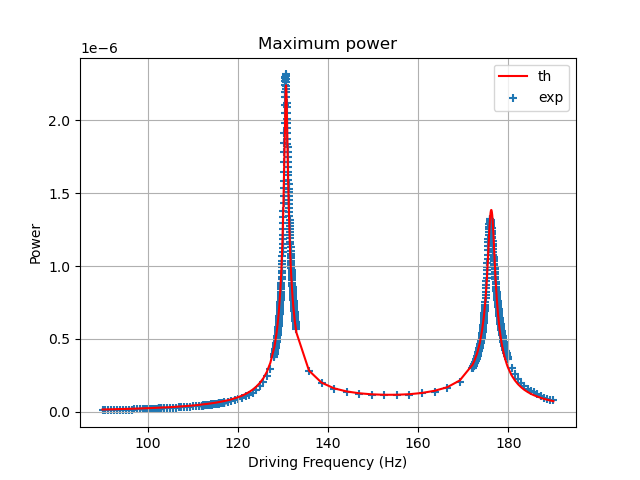

In [ ]:
plt.figure()
plt.plot(f_list, power_th.max(axis=0), 'r-', label="th")
plt.scatter(f_list, power1_exp.max(axis=0), marker='+',label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()